In [40]:
import os
import pandas as pd
import numpy as np
import matplotlib as plt
import networkx as nx
import mip

BUILDING_NAME = "Edificio2.csv"

ASCENDING_SPEED = 1.0
DESCENDING_SPEED = 2.0
HORIZONTAL_SPEED = 1.5

ASCENDING_ENERGY = 50
DESCENDING_ENERGY = 5
HORIZONTAL_ENERGY = 10

X_BASE_RANGE = range(-8, 6) if "Edificio1.csv" == BUILDING_NAME else range(-10, 11)
Y_BASE_RANGE = range(-17, -14) if "Edificio1.csv" == BUILDING_NAME else range(-31, -29)
Z_BASE = 0

BATTERY_CAPACITY = 3600 if "Edificio1.csv" == BUILDING_NAME else 21600  # 1 Wh is 3600 J

Y_ENTRY_POINT = -12.5 if "Edificio1.csv" == BUILDING_NAME else -20.0

# Reading CSV and creating pairs


In [41]:
# loading building csv data

nodes = pd.read_csv(BUILDING_NAME)

# Creating Bases and entry points

In [42]:
# Adding is_base and is_entry_point columns

nodes["is_base"] = False
nodes["is_entry_point"] = nodes["y"] <= Y_ENTRY_POINT

# Genero tutte le basi candidate come prima
bases = []
for x in X_BASE_RANGE:
    for y in Y_BASE_RANGE:
        bases.append(
            {"x": x, "y": y, "z": Z_BASE, "is_base": True, "is_entry_point": False}
        )

bases_df = pd.DataFrame(bases)

# Calcolo del centroide sui nodi di servizio
centroid_x = nodes["x"].mean()
centroid_y = nodes["y"].mean()

# Seleziono la base candidata più vicina al centroide (distanza euclidea su x,y)
bases_df["dist_centroid"] = np.hypot(
    bases_df["x"] - centroid_x, bases_df["y"] - centroid_y
)
nearest_idx = bases_df["dist_centroid"].idxmin()
selected_base = bases_df.loc[[nearest_idx]].drop(columns=["dist_centroid"])

# Mantengo solo i nodi di servizio + la base più vicina al centroide
building = pd.concat([nodes, selected_base], ignore_index=True)

building.to_csv("building.csv", index=False)
print(
    "Base scelta (più vicina al centroide): "
    f"(x={selected_base.iloc[0]['x']}, y={selected_base.iloc[0]['y']}, z={Z_BASE})"
)

Base scelta (più vicina al centroide): (x=-3, y=-30, z=0)


# Merging nodes to create pairs

In [43]:
# setting node numbering from 1 to n
building.index += 1

# generating all possible pairs of points (edges)
nodes_pairs = (
    building.rename_axis("source_node")
    .reset_index()
    .merge(building.rename_axis("target_node").reset_index(), how="cross")
)

# removing self-self pairs
nodes_pairs = nodes_pairs[
    nodes_pairs["source_node"] != nodes_pairs["target_node"]
]  # keeping only pairs with different points

In [44]:
first_point_cols = ["x_x", "y_x", "z_x"]
second_point_cols = ["x_y", "y_y", "z_y"]
diff_cols = ["dx", "dy", "dz"]

# Computing distances 

In [45]:
# function to determine if two points are connected based on distance and coordinate deltas


def process_connections(dataframe):
    # distances and deltas on coordinates
    dataframe[diff_cols] = (
        dataframe[second_point_cols].values - dataframe[first_point_cols].values
    )
    dataframe["euclidean_distance"] = np.sqrt(
        (dataframe[diff_cols] ** 2).sum(axis=1)
    )  # axis=1 sum on columns

    # conditions near and tunnel
    condition_near = dataframe["euclidean_distance"] <= 4.0

    condition_tunnel = (
        ((dataframe["dx"].abs() <= 0.5) & (dataframe["dy"].abs() <= 0.5))
        | ((dataframe["dy"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
        | ((dataframe["dx"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
    )

    condition_tunnel_and_not_far = (
        dataframe["euclidean_distance"] <= 11.0
    ) & condition_tunnel

    # if the arc is from base to entry point or viceversa
    condition_base_to_entry_point = (
        (dataframe["is_base_x"]) & (dataframe["is_entry_point_y"])
    ) | ((dataframe["is_base_y"]) & (dataframe["is_entry_point_x"]))

    # l'unica connessione ammessa è base <-> entry point
    condition_involves_base = dataframe["is_base_x"] | dataframe["is_base_y"]

    # Gli archi tra nodi griglia usano le regole di distanza (near/tunnel)
    # Gli archi con basi usano SOLO la regola base <-> entry point
    dataframe["are_connected"] = (
        (condition_near & ~condition_involves_base)
        | (condition_tunnel_and_not_far & ~condition_involves_base)
        | condition_base_to_entry_point
    )
    return dataframe

In [46]:
nodes_pairs = process_connections(nodes_pairs)

nodes_pairs.to_csv("pairs.csv", index=False)

nodes_pairs.head()

,source_node,x_x,y_x,z_x,is_base_x,is_entry_point_x,target_node,x_y,y_y,z_y,is_base_y,is_entry_point_y,dx,dy,dz,euclidean_distance,are_connected
1,1,-15.7277,-18.288,79.3699,False,False,2,-16.9469,-14.8742,79.3699,False,False,-1.2192,3.4138,0.0,3.624980,True
2,1,-15.7277,-18.288,79.3699,False,False,3,-16.9469,-7.2542,79.3699,False,False,-1.2192,11.0338,0.0,11.100955,False
3,1,-15.7277,-18.288,79.3699,False,False,4,-19.1110,-7.2542,79.3699,False,False,-3.3833,11.0338,0.0,11.540861,False
4,1,-15.7277,-18.288,79.3699,False,False,5,-20.7264,-5.9131,79.3699,False,False,-4.9987,12.3749,0.0,13.346353,False
5,1,-15.7277,-18.288,79.3699,False,False,6,-20.7264,-3.4138,79.3699,False,False,-4.9987,14.8742,0.0,15.691680,False


In [47]:
# computing vertical distances on z and distances on horizontal plane x,y
nodes_pairs["d_horizontal"] = np.sqrt(nodes_pairs["dx"] ** 2 + nodes_pairs["dy"] ** 2)
nodes_pairs["d_vertical"] = nodes_pairs["dz"]

# dropping columns that are not useful anymore
nodes_pairs.drop(columns=["dx", "dy", "dz"], inplace=True)
nodes_pairs.drop(columns=["x_x", "y_x", "z_x", "x_y", "y_y", "z_y"], inplace=True)

# keeping only connected pairs
nodes_pairs = nodes_pairs[nodes_pairs["are_connected"] == True]
nodes_pairs.drop(columns=["are_connected"], inplace=True)

nodes_pairs.head(5)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,euclidean_distance,d_horizontal,d_vertical
1,1,False,False,2,False,False,3.62498,3.62498,0.0000
40,1,False,False,41,False,False,3.84050,3.84050,0.0000
41,1,False,False,42,False,False,4.38910,0.00000,-4.3891
82,1,False,False,83,False,False,9.87550,0.00000,-9.8755
653,1,False,False,654,False,False,7.74190,7.74190,0.0000


# Function for time travel

In [48]:
# finding rows corresponding to different movement types

d_horizontal = nodes_pairs["d_horizontal"]
d_vertical = nodes_pairs["d_vertical"]
rows_horizontal = d_vertical == 0
rows_ascending = (d_horizontal == 0) & (d_vertical > 0)
rows_descending = (d_horizontal == 0) & (d_vertical < 0)
rows_oblique_ascending = (d_horizontal != 0) & (d_vertical > 0)
rows_oblique_descending = (d_horizontal != 0) & (d_vertical < 0)

In [49]:
# function for time travel based on movement types and speeds


def compute_time_travel(dataframe):
    dataframe.loc[rows_horizontal, "time_travel"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] / HORIZONTAL_SPEED
    )

    dataframe.loc[rows_ascending, "time_travel"] = (
        dataframe.loc[rows_ascending, "d_vertical"] / ASCENDING_SPEED
    )
    dataframe.loc[rows_descending, "time_travel"] = (
        -dataframe.loc[rows_descending, "d_vertical"] / DESCENDING_SPEED
    )

    dataframe.loc[rows_oblique_ascending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] / HORIZONTAL_SPEED,
        dataframe.loc[rows_oblique_ascending, "d_vertical"] / ASCENDING_SPEED,
    )

    dataframe.loc[rows_oblique_descending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_descending, "d_horizontal"] / HORIZONTAL_SPEED,
        -dataframe.loc[rows_oblique_descending, "d_vertical"] / DESCENDING_SPEED,
    )
    return dataframe

# Function for energy consumption


In [50]:
# function for energy cost based on movement types and energy consumption rates


def compute_energy_cost(dataframe):
    dataframe.loc[rows_horizontal, "energy_consumption"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] * HORIZONTAL_ENERGY
    )

    dataframe.loc[rows_ascending, "energy_consumption"] = (
        dataframe.loc[rows_ascending, "d_vertical"] * ASCENDING_ENERGY
    )
    dataframe.loc[rows_descending, "energy_consumption"] = (
        -dataframe.loc[rows_descending, "d_vertical"] * DESCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_ascending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] * HORIZONTAL_ENERGY
        + dataframe.loc[rows_oblique_ascending, "d_vertical"] * ASCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_descending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_descending, "d_horizontal"] * HORIZONTAL_ENERGY
        + -dataframe.loc[rows_oblique_descending, "d_vertical"] * DESCENDING_ENERGY
    )
    return dataframe

# Actually computing energy and time costs for arcs

In [51]:
# computing time travel and energy cost for each pair (edges)

nodes_pairs = compute_time_travel(nodes_pairs)

nodes_pairs = compute_energy_cost(nodes_pairs)

# rounding to 2 decimal places
nodes_pairs["time_travel"] = nodes_pairs["time_travel"].round(2)
nodes_pairs["energy_consumption"] = nodes_pairs["energy_consumption"].round(2)

nodes_pairs.drop(
    columns=["d_horizontal", "d_vertical", "euclidean_distance"], inplace=True
)

nodes_pairs.head(10)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,time_travel,energy_consumption
1,1,False,False,2,False,False,2.42,36.25
40,1,False,False,41,False,False,2.56,38.40
41,1,False,False,42,False,False,2.19,21.95
82,1,False,False,83,False,False,4.94,49.38
653,1,False,False,654,False,False,5.16,77.42
697,2,False,False,1,False,False,2.42,36.25
699,2,False,False,3,False,False,5.08,76.20
739,2,False,False,43,False,False,2.19,21.95
780,2,False,False,84,False,False,4.94,49.38
1395,3,False,False,2,False,False,5.08,76.20


In [52]:
# Pruning degli archi: manteniamo gli archi più corti sia in uscita che in entrata per garantire la connettività
k_keep = 20

# Archi migliori in uscita (per garantire out-degree >= 1)
out_edges = nodes_pairs.sort_values("time_travel").groupby("source_node").head(k_keep)

# Archi migliori in entrata (per garantire in-degree >= 1)
in_edges = nodes_pairs.sort_values("time_travel").groupby("target_node").head(k_keep)

# Unione degli archi per evitare nodi isolati
nodes_pairs = pd.concat([out_edges, in_edges]).drop_duplicates()

print(f"Pruning completato. Archi rimanenti: {len(nodes_pairs)}")

Pruning completato. Archi rimanenti: 4672


# Creating Graph with Networkx


In [53]:
# creating directed graph G from the dataframe of edges with costs

G = nx.from_pandas_edgelist(
    nodes_pairs,  # dataframe containing edges
    source="source_node",  # indicating the start of the edge
    target="target_node",  # indicating the end of the edge
    edge_attr=["time_travel", "energy_consumption"],  # edge costs
    create_using=nx.DiGraph(),  # creating an oriented graph
)

# nx.draw_networkx(G, node_size=50, font_size=8)

# Clustering per viaggi (zone connesse base↔nodi)

In [60]:
# Clustering dei nodi in zone: ogni nodo deve essere raggiungibile dalla base e tornare alla base
base_nodes = building[building["is_base"] == True].index.tolist()
if len(base_nodes) != 1:
    print(f"WARNING: numero basi attive = {len(base_nodes)}. Uso la prima.")
active_base = base_nodes[0] if base_nodes else None

service_nodes = building[building["is_base"] == False].index.tolist()

# Raggiungibilità dalla base (andata) e verso la base (ritorno) con pesi (energia)
reachable_from_base = (
    nx.single_source_dijkstra_path_length(G, active_base, weight="energy_consumption")
    if active_base is not None
    else {}
)
reachable_to_base = (
    nx.single_source_dijkstra_path_length(
        G.reverse(), active_base, weight="energy_consumption"
    )
    if active_base is not None
    else {}
)

valid_nodes = [
    n for n in service_nodes if n in reachable_from_base and n in reachable_to_base
]

# Cluster = componenti connesse (non orientate) tra i nodi validi
G_valid_und = G.subgraph(valid_nodes).to_undirected()
clusters = [sorted(list(c)) for c in nx.connected_components(G_valid_und)]
clusters = sorted(clusters, key=len, reverse=True)

print(f"Nodi servizio totali: {len(service_nodes)}")
print(f"Nodi validi base↔nodo: {len(valid_nodes)}")
print(f"Cluster trovati: {len(clusters)}")
print("Dimensioni cluster:", [len(c) for c in clusters])

# Ogni cluster è un viaggio
trips = clusters

Nodi servizio totali: 696
Nodi validi base↔nodo: 696
Cluster trovati: 1
Dimensioni cluster: [696]


In [ ]:
# Split cluster grandi in blocchi fortemente connessi da ~70-100 nodi
MAX_CLUSTER_SIZE = 100
TARGET_MIN = 70


def strong_chunks(Gdir, nodes, max_size=MAX_CLUSTER_SIZE):
    remaining = set(nodes)
    parts = []
    while remaining:
        seed = next(iter(remaining))
        current = [seed]
        remaining.remove(seed)
        frontier = set(Gdir.successors(seed)).union(Gdir.predecessors(seed))
        frontier &= remaining
        while frontier and len(current) < max_size:
            added = None
            for cand in list(frontier):
                trial = current + [cand]
                if nx.is_strongly_connected(Gdir.subgraph(trial)):
                    added = cand
                    break
            if added is None:
                break
            current.append(added)
            remaining.remove(added)
            frontier |= set(Gdir.successors(added)).union(Gdir.predecessors(added))
            frontier &= remaining
            # stop if reached max size
        parts.append(current)
    return parts


trips = []
for c in clusters:
    Gc = G.subgraph(c)
    if len(c) <= MAX_CLUSTER_SIZE and nx.is_strongly_connected(Gc):
        trips.append(c)
    else:
        subparts = strong_chunks(Gc, c, max_size=MAX_CLUSTER_SIZE)
        trips.extend(subparts)

print(f"Viaggi proposti (dopo split): {len(trips)}")
sizes = [len(t) for t in trips]
print("Dimensioni viaggi:", sizes)
print(f"Min={min(sizes)}, Max={max(sizes)}, Media={sum(sizes)/len(sizes):.1f}")
if any(s > MAX_CLUSTER_SIZE for s in sizes):
    print(
        "WARNING: alcuni viaggi superano la soglia, aumentare max_size o affinare split."
    )
if any(s < TARGET_MIN for s in sizes):
    print("Nota: alcuni viaggi sono più piccoli di ~70 nodi (OK se va bene).")

Viaggi proposti (dopo split): 12
Dimensioni viaggi: [100, 100, 100, 100, 100, 100, 1, 11, 28, 12, 1, 43]
Min=1, Max=100, Media=58.0
Nota: alcuni viaggi sono più piccoli di ~70 nodi (OK se va bene).


In [ ]:
# Diagnostica: connettività forte del viaggio + base↔nodi
def cluster_diagnostics(cluster_nodes):
    Gsub = G.subgraph(cluster_nodes)
    strong_conn = nx.is_strongly_connected(Gsub) if len(cluster_nodes) > 1 else True
    base_ok = all(
        (n in reachable_from_base) and (n in reachable_to_base) for n in cluster_nodes
    )
    return strong_conn, base_ok


missing_nodes = sorted(list(set(service_nodes) - set(valid_nodes)))
if missing_nodes:
    print(f"WARNING: {len(missing_nodes)} nodi servizio NON base↔nodo.")
else:
    print("OK: tutti i nodi servizio sono base↔nodo.")

covered = set().union(*trips) if trips else set()
if covered != set(valid_nodes):
    diff_missing = sorted(list(set(valid_nodes) - covered))
    diff_extra = sorted(list(covered - set(valid_nodes)))
    print(
        f"ATTENZIONE: copertura incongruente. Missing={len(diff_missing)}, Extra={len(diff_extra)}"
    )
else:
    print("OK: copertura totale dei nodi validi nei viaggi.")

for idx, cluster_nodes in enumerate(trips, start=1):
    strong_conn, base_ok = cluster_diagnostics(cluster_nodes)
    status = "OK" if strong_conn and base_ok else "CHECK"
    print(
        f"Viaggio {idx}: size={len(cluster_nodes)} | strong_conn={strong_conn} | base↔nodi={base_ok} | {status}"
    )

OK: tutti i nodi servizio sono base↔nodo.
OK: copertura totale dei nodi validi nei viaggi.
Viaggio 1: size=100 | strong_conn=True | base↔nodi=True | OK
Viaggio 2: size=100 | strong_conn=True | base↔nodi=True | OK
Viaggio 3: size=100 | strong_conn=True | base↔nodi=True | OK
Viaggio 4: size=100 | strong_conn=True | base↔nodi=True | OK
Viaggio 5: size=100 | strong_conn=True | base↔nodi=True | OK
Viaggio 6: size=100 | strong_conn=True | base↔nodi=True | OK
Viaggio 7: size=1 | strong_conn=True | base↔nodi=True | OK
Viaggio 8: size=11 | strong_conn=True | base↔nodi=True | OK
Viaggio 9: size=28 | strong_conn=True | base↔nodi=True | OK
Viaggio 10: size=12 | strong_conn=True | base↔nodi=True | OK
Viaggio 11: size=1 | strong_conn=True | base↔nodi=True | OK
Viaggio 12: size=43 | strong_conn=True | base↔nodi=True | OK


# MODELLO MIP

In [17]:
# IL DATAFRAME BASES CONTIENE TUTTE LE BASI
# IL DATAFRAME NODES CONTIENE I NODI DEL SET S
# IL NODES_PAIRS CONTIENE GLI ARCHI TRA TUTTI I NODI
# IL SET H È UN INSIEME DI NUMERI DA 0 A UN NUMERO k CHE VA STIMATO BENE

m = mip.Model("DroneTourPlanning", solver_name=mip.CBC)
m.threads = -1  # Usa tutti i thread disponibili
m.__max_mip_gap = 0.5

# SETS AND PARAMETERS
# ---------------------------------------------------------------
N = building.index.tolist()  # All nodes
S = building[building["is_base"] == False].index.tolist()  # Service nodes
B = building[building["is_base"] == True].index.tolist()  # Bases nodes
print(f"set N = {N}")
print(f"set B = {B}")
print(f"set S = {S}")

A = G.edges  # set of arcs
print(f"set A = {A}")
print(f"number of arcs |A| = {len(A)}")

t = {
    (u, v): data["time_travel"] for u, v, data in G.edges(data=True)
}  # dictionary of time travel costs
e = {
    (u, v): data["energy_consumption"] for u, v, data in G.edges(data=True)
}  # dictionary of energy consumption costs
print(f"time travel costs t = {t}")
print(f"energy consumption costs e = {e}")

C = BATTERY_CAPACITY  # battery capacity

set N = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220,

# H E BIG M

In [18]:
# Calculate |H| according to formula: ceil(sum(e_in_min + e_out_min)/C * 1.5)
import math

min_energy_in_out = {}
for i in S:
    incoming = [e[j, i] for j in N if (j, i) in A]
    outgoing = [e[i, j] for j in N if (i, j) in A]

    # Check for connectivity to avoid OverflowError
    min_energy_in = min(incoming) if incoming else 0
    min_energy_out = min(outgoing) if outgoing else 0

    if not incoming or not outgoing:
        print(
            f"Warning: Node {i} has no {'incoming' if not incoming else 'outgoing'} edges!"
        )

    min_energy_in_out[i] = min_energy_in + min_energy_out

sum_min_energies = sum(min_energy_in_out.values())
# Included the * 1.5 factor from the formula description
H_length = math.ceil((sum_min_energies / C) * 1.5)
H = list(range(1, max(2, H_length + 1)))  # At least 1-2 tours

print(f"set H = {H}")

positive_energy = [value for value in e.values() if value > 0]
print(np.mean(positive_energy))
M = math.ceil(min(len(S), C / (np.mean(positive_energy)))) + 10
print(f"Constant M for flow constraints: {M}")

set H = [1, 2, 3]
65.83404856952762
Constant M for flow constraints: 339


# VARIABILI

In [19]:
# VARIABLES
# ---------------------------------------------------------------
x = {
    (i, j, h): m.add_var(var_type=mip.BINARY, name=f"x_{i}_{j}_{h}")
    for i, j in A
    for h in H
}  # binary variable indicating if arc (i,j) is used in tour h


# SCF (Single Commodity Flow) variables for subtour elimination
# f[i,j,h] = flow on arc (i,j) in tour h
f = {
    (i, j, h): m.add_var(lb=0, ub=len(S), name=f"f_{i}_{j}_{h}")
    for i, j in A
    for h in H
}

# OBJ FUNCTION


In [20]:
m.objective = mip.minimize(mip.xsum(t[i, j] * x[i, j, h] for i, j in A for h in H))

# CONSTRAINTS

In [21]:
# (2) Each service node is visited at least once
for i in S:
    m += mip.xsum(x[j, i, h] for j in N for h in H if (j, i) in A) >= 1

# (3) Flow conservation for x (arc variables)
for i in N:
    for h in H:
        m += mip.xsum(x[j, i, h] for j in N if (j, i) in A) == mip.xsum(
            x[i, j, h] for j in N if (i, j) in A
        )

# (5) Energy constraint
for h in H:
    m += mip.xsum(e[i, j] * x[i, j, h] for (i, j) in A) <= C

# (6) SCF Subtour Elimination
# Idea: il flusso parte dalla base e viene consumato ad ogni nodo visitato.
# Se c'è un sottotour senza base, non ha sorgente di flusso → infeasible.

# (6a) f_ij <= |S| * x_ij (flow only on active arcs)
for i, j in A:
    for h in H:
        m += f[i, j, h] <= M * x[i, j, h]

# (6b) Flow conservation at service nodes: inflow - outflow = 1 if visited
for i in S:
    for h in H:
        inflow = mip.xsum(f[j, i, h] for j in N if (j, i) in A)
        outflow = mip.xsum(f[i, j, h] for j in N if (i, j) in A)
        visits = mip.xsum(x[j, i, h] for j in N if (j, i) in A)
        m += inflow - outflow == visits

# (6c) Flow at bases: la base è sorgente, il flusso netto uscente >= 0
# Non serve vincolo esplicito: i vincoli (6b) impongono già che il flusso
# totale consumato = nodi visitati. La base è l'unica sorgente possibile.

# (7) Symmetry Breaking
for h in range(len(H) - 1):
    m += mip.xsum(x[i, j, H[h]] for (i, j) in A) >= mip.xsum(
        x[i, j, H[h + 1]] for (i, j) in A
    )

In [ ]:
# GREEDY PATH-BASED (Dijkstra precompute) CHE PROVA A COPRIRE TUTTI I NODI E IMPOSTA WARM START
# ---------------------------------------------------------------
import math


def build_greedy_cover_all(N, S, B, A, e, C, H, active_base, G):
    """Tour greedy con Dijkstra precomputato per coprire S.
    Restituisce (soluzione, nodi_mancanti, nodi_irraggiungibili)."""
    unvisited = set(S)
    greedy_solution = {}

    # Precompute distanze fisse per scartare nodi palesemente inaccessibili
    dist_from_base = nx.single_source_dijkstra_path_length(
        G, active_base, weight="energy_consumption"
    )
    dist_to_base = nx.single_source_dijkstra_path_length(
        G.reverse(), active_base, weight="energy_consumption"
    )

    unreachable = set()
    for node in list(unvisited):
        if node not in dist_from_base or node not in dist_to_base:
            unreachable.add(node)
            unvisited.discard(node)
        elif dist_from_base[node] + dist_to_base[node] > C:
            unreachable.add(node)
            unvisited.discard(node)

    tour_count = 0
    for h in H:
        if not unvisited:
            break

        current = active_base
        energy_used = 0.0
        tour_count += 1

        while unvisited:
            # Calcola distanze dal nodo corrente
            try:
                dist_curr, paths_curr = nx.single_source_dijkstra(
                    G, current, weight="energy_consumption"
                )
            except:
                break

            candidates = []
            for target in unvisited:
                if target in dist_curr and target in dist_to_base:
                    cost_to = dist_curr[target]
                    cost_back = dist_to_base[target]
                    if energy_used + cost_to + cost_back <= C:
                        candidates.append((cost_to, cost_back, target))

            if not candidates:
                # Prova a rientrare alla base se possibile
                if active_base in dist_curr:
                    if energy_used + dist_curr[active_base] <= C:
                        path_back = paths_curr[active_base]
                        for u, v in zip(path_back[:-1], path_back[1:]):
                            greedy_solution[(u, v, h)] = 1
                break

            # Strategia: vai al nodo più vicino (closest)
            candidates.sort(key=lambda t: t[0])
            cost_to, cost_back, target = candidates[0]
            path_to = paths_curr[target]

            for u, v in zip(path_to[:-1], path_to[1:]):
                greedy_solution[(u, v, h)] = 1

            energy_used += cost_to
            current = target
            unvisited.remove(target)

        # Rientro finale forzato se non siamo in base
        if current != active_base:
            try:
                dist_curr, paths_curr = nx.single_source_dijkstra(
                    G, current, weight="energy_consumption"
                )
                if (
                    active_base in dist_curr
                    and energy_used + dist_curr[active_base] <= C
                ):
                    path_back = paths_curr[active_base]
                    for u, v in zip(path_back[:-1], path_back[1:]):
                        greedy_solution[(u, v, h)] = 1
            except:
                pass

    return greedy_solution, unvisited, unreachable


# ESECUZIONE GREEDY
print("Costruzione della soluzione greedy (Multi-Stage Dijkstra)...")
greedy_sol, missing, unreach = build_greedy_cover_all(N, S, B, A, e, C, H, B[0], G)

visited_count = len(S) - len(missing) - len(unreach)
print(f"Nodi totali: {len(S)}")
print(f"Nodi visitati: {visited_count}")
print(f"Nodi mancanti: {len(missing)}")
print(f"Nodi irraggiungibili: {len(unreach)}")

# IMPOSTAZIONE WARM START (Accesso diretto ai dizionari x e f)
start_sol = []

# 1. Imposta variabili x (Archi)
for (i, j, h), val in greedy_sol.items():
    if (i, j, h) in x:
        start_sol.append((x[i, j, h], 1.0))

# 2. Imposta variabili f (Flusso SCF) per aiutare la convergenza
for h in H:
    edges_h = [(i, j) for (i_loop, j_loop, h_loop) in greedy_sol.keys() if h_loop == h]
    if not edges_h:
        continue

    path_map = {u: v for u, v in edges_h}
    visited_nodes_tour = []
    temp_curr = B[0]
    loop_limit = 0
    while temp_curr in path_map and loop_limit < len(N):
        nxt = path_map[temp_curr]
        if nxt in S:
            visited_nodes_tour.append(nxt)
        temp_curr = nxt
        if temp_curr == B[0]:
            break
        loop_limit += 1

    n_vis = len(visited_nodes_tour)
    temp_curr = B[0]
    loop_limit = 0
    while temp_curr in path_map and loop_limit < len(N):
        nxt = path_map[temp_curr]
        if (temp_curr, nxt, h) in f:
            start_sol.append((f[temp_curr, nxt, h], float(n_vis)))
        if nxt in S:
            n_vis -= 1
        temp_curr = nxt
        if temp_curr == B[0]:
            break
        loop_limit += 1

if start_sol:
    m.start = start_sol
    print(f"Warm start caricato correttamente: {len(start_sol)} variabili impostate.")
else:
    print("Nessuna soluzione trovata dal greedy.")

Costruzione della soluzione greedy (Multi-Stage Dijkstra)...
Nodi totali: 696
Nodi visitati: 696
Nodi mancanti: 0
Nodi irraggiungibili: 0
Warm start caricato correttamente: 891 variabili impostate.


In [ ]:
print(f"Variabili: {m.num_cols}, Vincoli: {m.num_rows}")
m.optimize(max_seconds=7200)  # 2 hours of testing
print(f"\nStatus: {m.status}")

Variabili: 18168, Vincoli: 13964
Welcome to the CBC MILP Solver 
Version: Trunk
Build Date: Oct 24 2021 

Starting solution of the Linear programming relaxation problem using Dual Simplex

Clp0024I Matrix will be packed to eliminate 66 small elements
Coin0506I Presolve 13952 (-12) rows, 18159 (-9) columns and 93681 (-46) elements
Clp0014I Perturbing problem by 0.001% of 9.9537874 - largest nonzero change 0.00082509554 ( 0.070803256%) - largest zero change 0.00080798208
Clp0006I 3660  Obj 1252.8694 Primal inf 34928.356 (2088)
Clp0006I 7079  Obj 1313.3022 Primal inf 24832.779 (1898)
Clp0006I 9519  Obj 1396.7452 Primal inf 183226.02 (2553)
Clp0006I 11031  Obj 1429.9576 Primal inf 27184791 (3552)
Clp0006I 12028  Obj 1443.6256 Primal inf 27718521 (3753)
Clp0006I 13264  Obj 1459.5759 Primal inf 27052311 (3714)
Clp0006I 14243  Obj 1471.8801 Primal inf 7943513.6 (3910)
Clp0006I 15379  Obj 1487.9265 Primal inf 1.5643453e+08 (4187)
Clp0006I 16379  Obj 1497.7574 Primal inf 29025312 (4148)
Clp0006

In [ ]:
if m.objective_value:
    print(f"Obiettivo: {m.objective_value:.2f}")
if m.objective_bound:
    print(f"Lower bound: {m.objective_bound:.2f}")
gap = abs(m.objective_value - m.objective_bound) / abs(m.objective_value)
print(f"GAP: {gap:.4f}")
print(m.status)

Obiettivo: 165.43
Lower bound: 150.39
GAP: 0.0909
OptimizationStatus.FEASIBLE


In [ ]:
# Salvataggio del modello in formato leggibile
m.write("model.lp")

# Salvataggio della soluzione
if m.num_solutions:
    with open("solution.txt", "w") as file:
        file.write(f"Objective: {m.objective_value}\n")
        for var in m.vars:
            file.write(f"{var.name} = {var.x}\n")

In [ ]:
if m.num_solutions:

    # base unica già determinata
    active_base = B[0]
    # definisco per salvare i vari percorsi (path1, path2...)
    all_paths = []

    # in base al path in cui sono identifico gli archi che sono stati usati
    for idx, h in enumerate(H):
        # dizionario per salvare il nodo prossimo j dato il nodo i
        next_node = {}
        for i, j in A:
            if x[i, j, h].x == 1.0:
                # se è il primo arco creo una lista
                if i not in next_node:
                    next_node[i] = []
                # inserisco il nodo di arrivo j dato il nodo di partenza i
                # li metto in una lista perché dato un nodo i questo può avere più trasnizione di output
                next_node[i].append(j)

        # next_node[i] è la lista di tutti i nodi raggiungibili da i

        # lo stack sono i nodi da esplorare, parto dalla base
        stack = [active_base]
        path = []

        # finche c'è qualcosa nello stack vado avanti
        while stack:
            v = stack[-1]  # prendo ultimo elemento
            if v in next_node and next_node[v]:  # se v ha ancora archi non usati

                u = next_node[
                    v
                ].pop()  # prendo un nodo target (un arco) e lo rimuovo dalla lista
                stack.append(u)  # metto la destinazione nello stack
            else:
                # se non ha archi uscenti li ho già esplorati e la inserisco nello stack
                path.append(stack.pop())

        # il percorso è al contrario
        path = path[::-1]

        path_str = ["0"]  # base
        for node in path[1:]:
            if node == active_base:
                path_str.append("-0")
            else:
                path_str.append("-" + str(node))

        print(f"Viaggio {h}: {''.join(path_str)}")
        all_paths.append(path)

Viaggio 1: 0-44-49-44-41-45-48-53-47-46-42-43-50-18-17-51-55-35-27-39-64-63-21-60-59-24-20-1-4-8-11-15-14-13-16-12-5-6-9-10-7-3-2-19-23-58-62-61-38-54-34-22-57-26-30-31-32-29-25-37-33-0
Viaggio 2: 0-36-28-40-56-52-0


In [ ]:
# Validazione finale: Verifica copertura completa dei nodi S
visited_nodes = set()

# Un nodo i è visitato se esiste almeno un arco entrante attivo in un qualsiasi viaggio h
for i in S:
    is_visited = False
    for h in H:
        # Check incoming edges to i
        if any(x[j, i, h].x > 0.5 for j in N if (j, i) in A):
            is_visited = True
            break

    if is_visited:
        visited_nodes.add(i)

missing_nodes = set(S) - visited_nodes

if not missing_nodes:
    print(f"SUCCESS: Tutti i {len(S)} nodi di servizio sono stati visitati.")
else:
    print(f"WARNING: {len(missing_nodes)} nodi su {len(S)} NON sono stati visitati!")
    print(f"Lista nodi mancanti: {sorted(list(missing_nodes))}")

SUCCESS: Tutti i 64 nodi di servizio sono stati visitati.


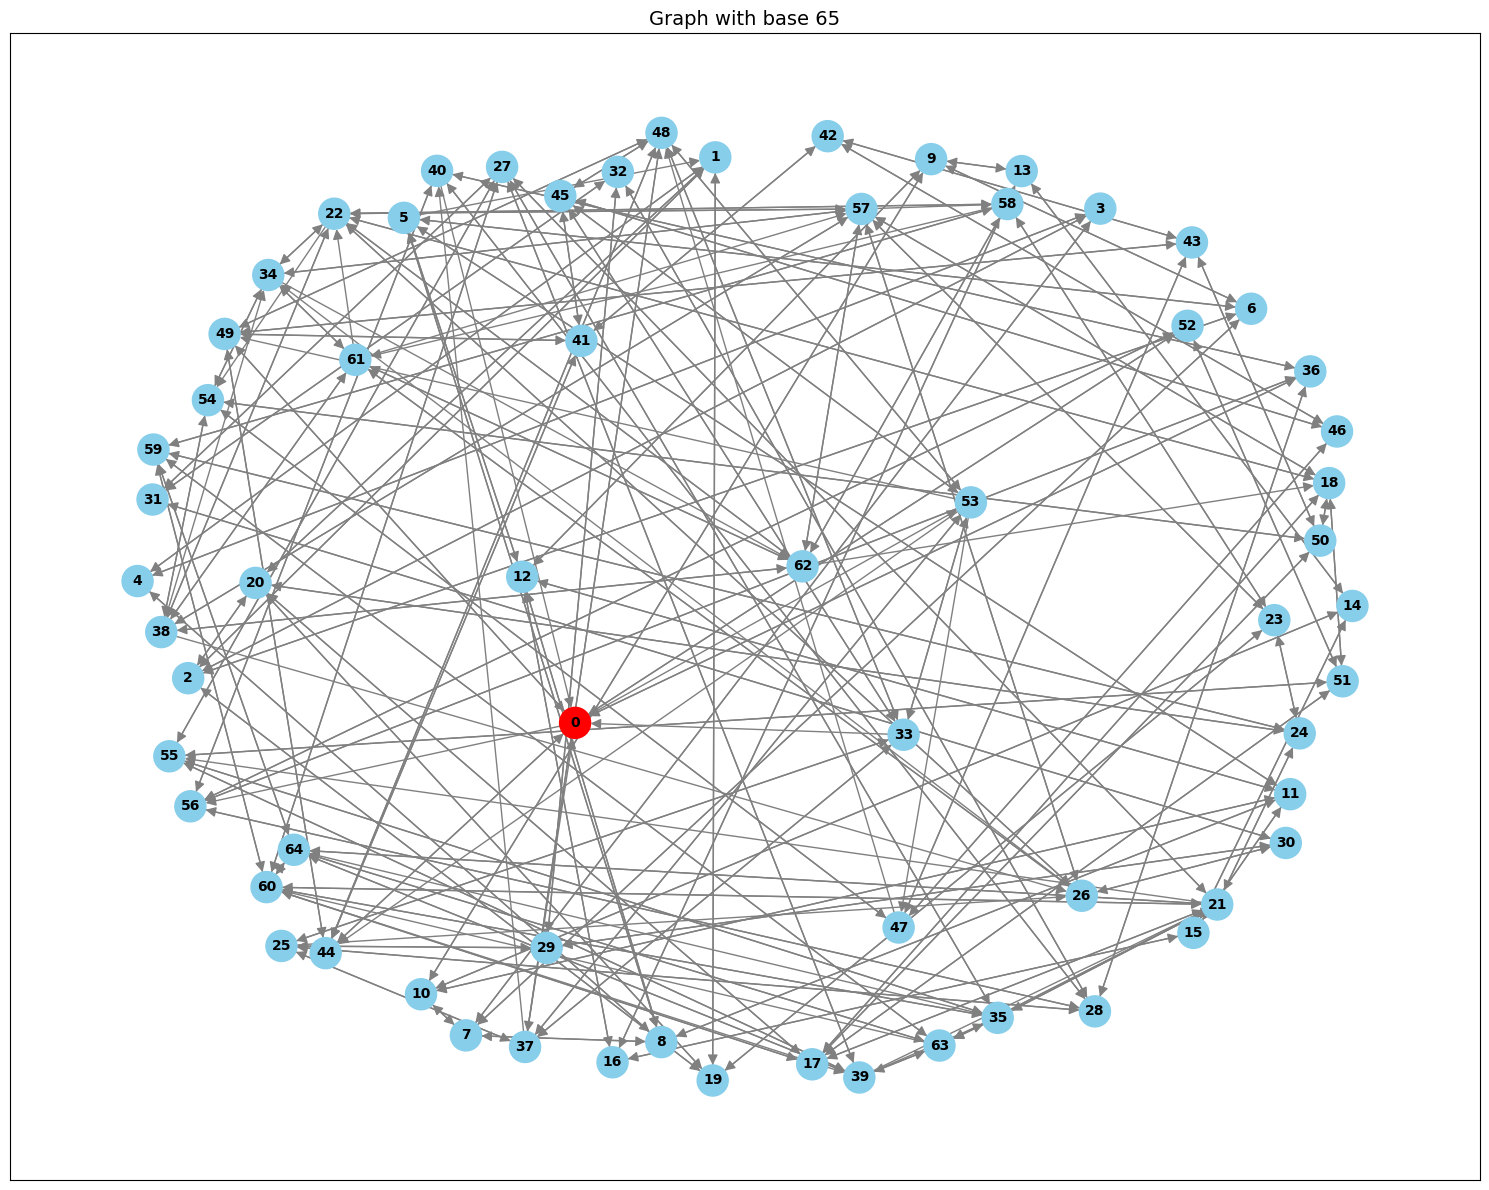

In [ ]:
import matplotlib.pyplot as plt

# creo una lista delle basi da rimuovere

remove_bases = [b for b in B if b != active_base]
# print(basi_da_rimuovere)

# creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(15, 12))

# k controlla la distanza tra i nodi
pos = nx.spring_layout(G_sub, k=2, iterations=50, seed=42)

# colore rosso per la base
node_colors = ["red" if n == active_base else "skyblue" for n in G_sub.nodes()]

# 0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

nx.draw_networkx(
    G_sub,
    pos=pos,
    labels=labels,
    node_size=500,
    node_color=node_colors,
    font_size=10,
    font_weight="bold",
    edge_color="gray",
    arrows=True,
    arrowsize=15,
)

plt.title(f"Graph with base {active_base}", fontsize=14)
# plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_3045/2277251425.py:66: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12)


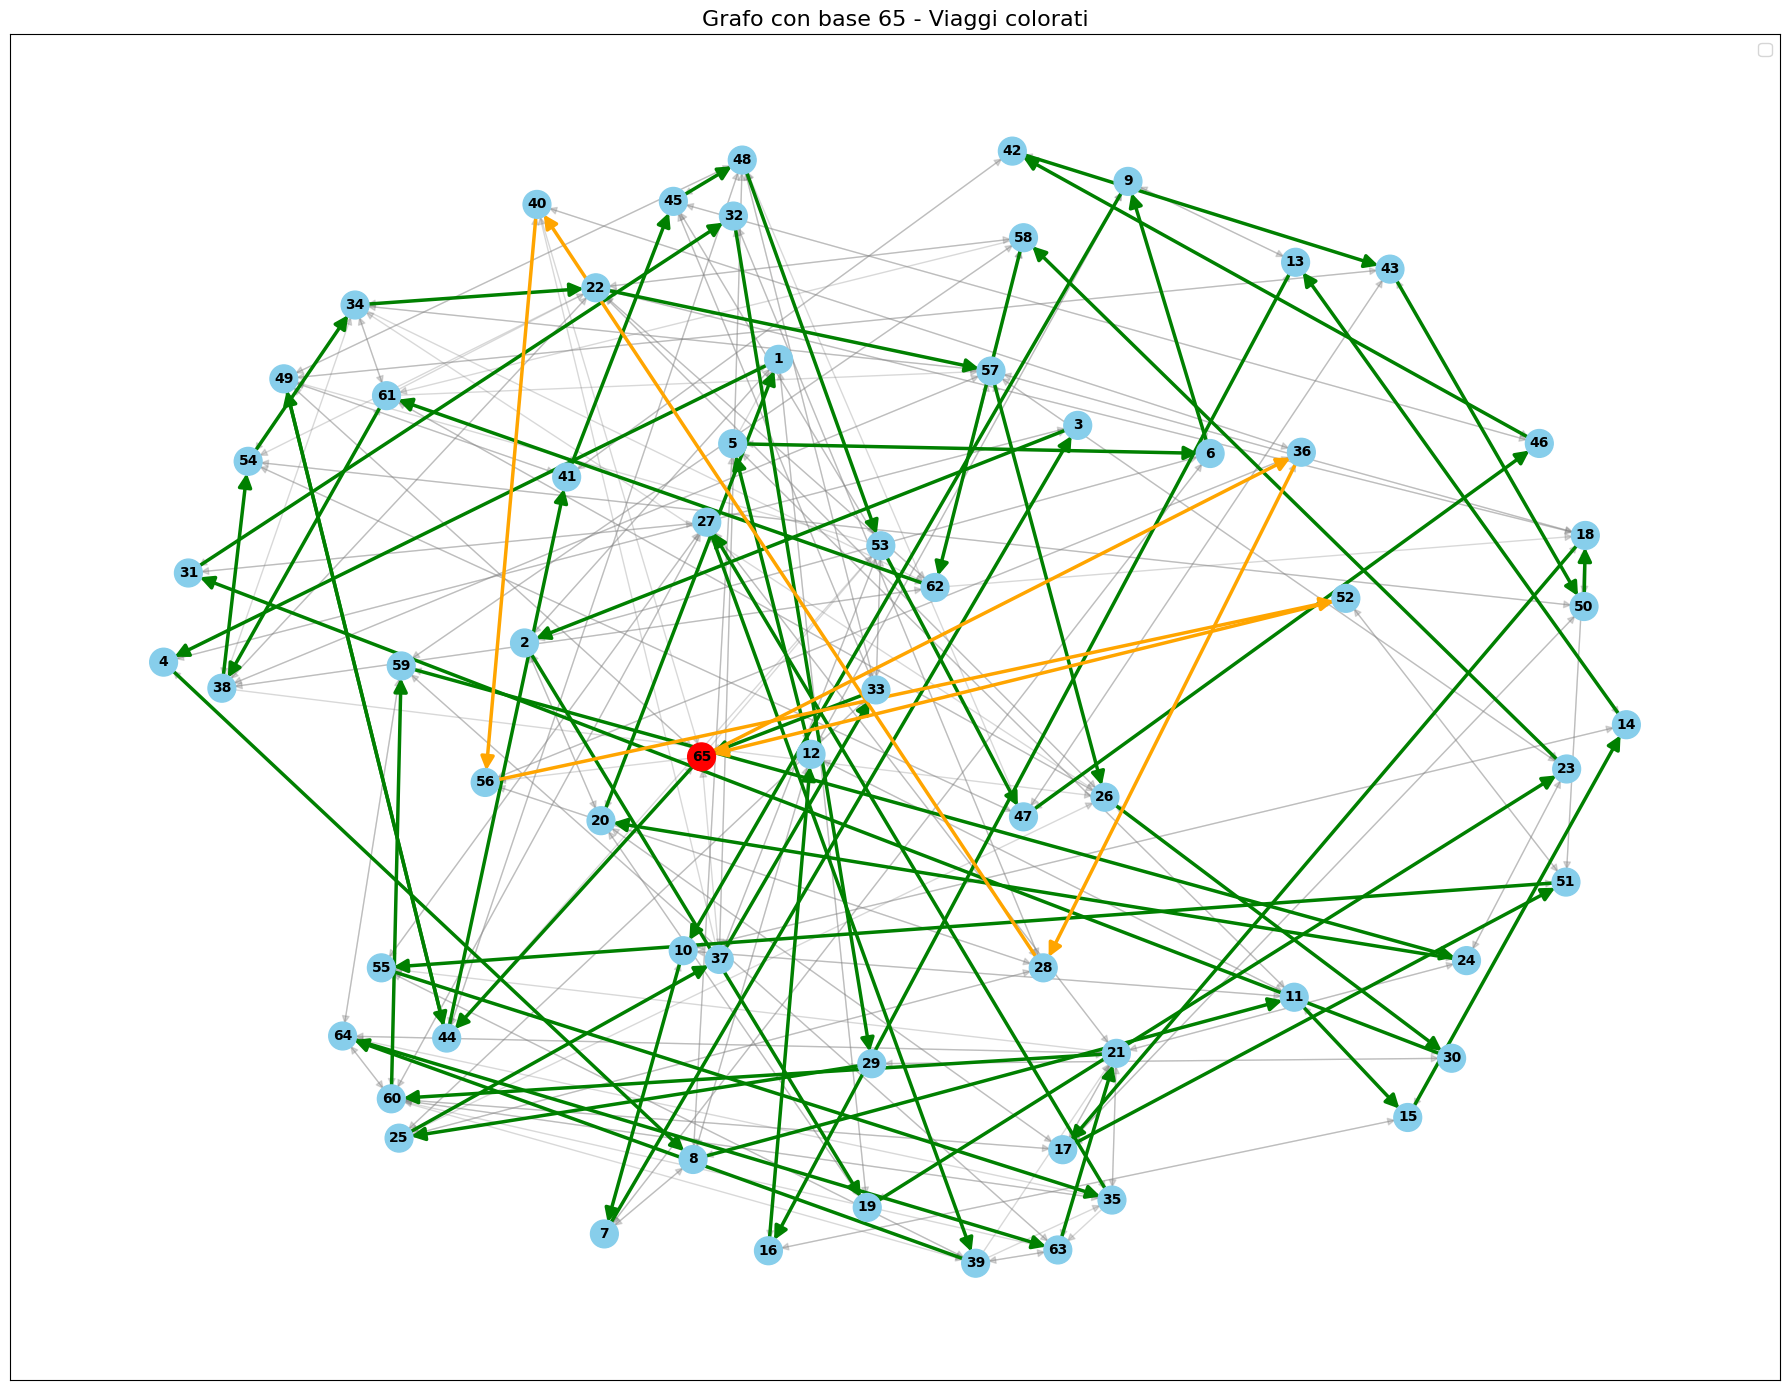

In [ ]:
import matplotlib.pyplot as plt

# creo una lista delle basi da rimuovere

remove_bases = [b for b in B if b != active_base]
# print(basi_da_rimuovere)

# creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(18, 14))

# k controlla la distanza tra i nodi
pos = nx.spring_layout(G_sub, k=2.5, iterations=100, seed=42)


node_colors = ["red" if n == active_base else "skyblue" for n in G_sub.nodes()]

# 0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

# Estrai gli archi dai path
path_edges = [[], []]  # lista di archi per ogni path
colors_path = ["green", "orange"]  # colori per i due path

for idx, path in enumerate(all_paths):

    # all_paths contiene già liste di interi
    # creo coppie di archi
    for i in range(len(path) - 1):
        path_edges[idx].append((path[i], path[i + 1]))

# disegno i nodi
nx.draw_networkx_nodes(G_sub, pos, node_size=400, node_color=node_colors)
nx.draw_networkx_labels(G_sub, pos, font_size=10, font_weight="bold")

# collego tutti i nodi
all_path_edges = set(path_edges[0] + path_edges[1])
other_edges = [e for e in G_sub.edges() if e not in all_path_edges]
nx.draw_networkx_edges(
    G_sub,
    pos,
    edgelist=other_edges,
    edge_color="gray",
    arrows=True,
    arrowsize=12,
    alpha=0.3,
)

# archi dei path
for idx, edges in enumerate(path_edges):

    nx.draw_networkx_edges(
        G_sub,
        pos,
        edgelist=edges,
        edge_color=colors_path[idx],
        arrows=True,
        arrowsize=20,
        width=2.5,
        label=f"Viaggio {idx+1}",
    )

plt.title(f"Grafo con base {active_base} - Viaggi colorati", fontsize=16)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()